# 043 — Check the downloaded records' spectra against the database

Before the downloaded records are used in any analysis, this notebook checks that they are the records
the selection actually chose. Every selected record has two spectra that should agree:

* the spectrum stored in the selection database (**DB spectrum**, `04_gm_database_for_selection/ESM-NGAsub_combined.csv`),
  which is what the GCIM selection saw, and
* the spectrum we compute from the downloaded time history (**TH spectrum**, `07_gm_records/spectra/acc_spectra.pickle`).

If a record was downloaded correctly and processed the same way, the two should match closely. A clear mismatch means
something went wrong between selection and download: the wrong record, component, units or processing.

**Step 1 (this section): how closely do the two spectra agree, with the records labelled as they currently are?**

Definitions (backend: `phd_project/scripts/timehistory_spectra_verification.py`):

* Compared only at the **DB periods** that lie inside the TH grid (0.02–6.0 s): 31 periods, 0.025–6.0 s.
  The TH spectrum is interpolated to them linearly in log T – log SA (nearly all lie exactly on the 0.01 s TH grid anyway).
* `diff = SA_TH − SA_DB` [g] and `pct = 100 (SA_TH − SA_DB) / SA_DB` [%] — signed, relative to the DB.
* Each record is summarised by its **mean squared logarithmic error** over the $N_T$ scored periods,
  $$\text{MSLE} = \frac{1}{N_T} \sum_{j=1}^{N_T} \left[ \ln S_{A,\text{TH}}(T_j) - \ln S_{A,\text{DB}}(T_j) \right]^2 .$$
  It is scale-free (a strong and a weak record count equally), symmetric (a factor 2 too high or too low scores the
  same), and a mean, so records scored over different numbers of periods stay comparable. $\sqrt{\text{MSLE}}$ is the
  typical log error, and $e^{\sqrt{\text{MSLE}}} - 1$ the typical relative error: MSLE = 0.0001 ≈ 1 %, 0.01 ≈ 10 %,
  0.05 ≈ 25 %, 0.5 ≈ a factor 2. The earlier metric, the sum of squared % errors (`summary["sse_pct"]`, %²), is still
  computed and can be chosen with `metric="sse_pct"`.
* **Only periods up to the record's maximum usable period are scored** (`max_usable_T` in the DB, the longest
  period its high-pass filtering leaves trustworthy; `use_max_usable_T=True`, the default everywhere). Beyond it the DB
  ordinates are small and filter-affected, and on a % scale they can swamp the score. Records are therefore scored over
  26–31 periods (`summary["n_periods"]`); in the plots the excluded range is shaded grey.
* **Ambiguous tags:** the CSV stores every ESM `location_code` as `00`, so a few downloaded tags match two DB rows.
  They are kept out of the histogram and listed separately.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
from phd_project.scripts import timehistory_spectra_verification as tsv

pd.set_option("display.width", 200)

# Both loaders are cached, so later calls (plots, per-tag lookups) do not re-read the files.
th = tsv.load_th_spectra()
db = tsv.load_db_spectra()

# Sanity check: every TH tag must find at least one DB row.
unmatched = sorted(set(th.index) - set(db["tag"]))
print(f"TH spectra: {len(th)} records, {th.shape[1]} periods ({th.columns.min()}-{th.columns.max()} s)")
print(f"TH tags without a DB row: {len(unmatched)}")

TH spectra: 2342 records, 599 periods (0.02-6.0 s)
TH tags without a DB row: 0


## 1. Per-record comparison: histogram of the MSLE

compared periods: 31 (0.025-6.0 s)
records compared: 2342  (ambiguous: 7, in histogram: 2335)


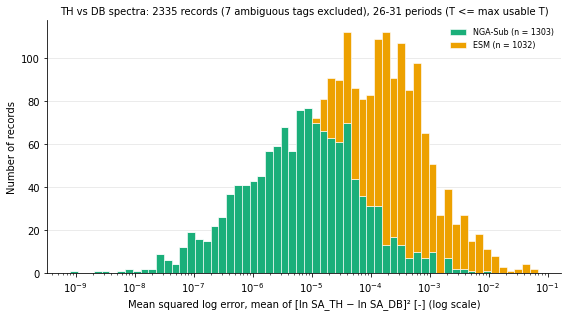

In [3]:
per_period, summary = tsv.compare_all(th, db)

n_amb = summary.loc[summary["ambiguous"]].index.get_level_values("tag").nunique()
print(f"compared periods: {per_period['period'].nunique()} "
      f"({per_period['period'].min()}-{per_period['period'].max()} s)")
print(f"records compared: {summary.index.get_level_values('tag').nunique()}  "
      f"(ambiguous: {n_amb}, in histogram: {(~summary['ambiguous']).sum()})")

# Log x-axis: the MSLE spans many orders of magnitude. A few gross outliers (MSLE ~100, i.e. a
# factor ~e^10) would squash everything else, so they are left off the axis (x_max) and listed in
# the next cell instead.
X_MAX = 5
fig, ax = tsv.plot_error_histogram(summary, metric="msle", x_max=X_MAX)

Records beyond the histogram's x-axis (`msle > X_MAX`):

In [4]:
cols = ["msle", "max_pos_pct", "T_max_pos", "max_neg_pct", "T_max_neg"]
summary.loc[~summary["ambiguous"] & (summary["msle"] > X_MAX), cols].sort_values("msle")

,,msle,max_pos_pct,T_max_pos,max_neg_pct,T_max_neg
tag,db_row,,,,,


## 2. Ambiguous tags (two DB rows each) — excluded from the histogram above

In [5]:
summary.loc[summary["ambiguous"], ["msle", "max_pos_pct", "T_max_pos", "max_neg_pct", "T_max_neg"]].round(4)

msle  max_pos_pct  T_max_pos  max_neg_pct  T_max_neg
tag                             db_row                                                        
EMSC-20130615_0000050_IMMV_0__U 1868    0.0009       0.3812       0.10     -14.9023        4.5
                                1873    0.0010       2.4600       0.10     -13.1401        4.5
EMSC-20131012_0000044_IMMV_0__U 2247    0.0008       0.4663       0.15     -11.1667        6.0
                                2256    0.0008       0.4686       0.15     -11.0522        6.0
EMSC-20131012_0000044_KTHA_0__U 2249    0.0004       0.5603       0.15      -7.4048        4.5
                                2259    0.0004       2.6426       0.15      -5.2897        4.5
EMSC-20131012_0000044_KTHA_0__V 22580   0.0006       2.0769       0.07      -3.7865        3.5
                                22590   0.0001       4.1789       0.07      -1.8693        3.5
EMSC-20140126_0000046_IMMV_0__U 2576    0.0001       0.9656       0.05      -4.9459        4.5
                                2582    0.0004       3.0553       0.05      -2.9772        4.5
EMSC-20140126_0000085_KTHA_0__V 22958   0.0000       1.8013       0.10      -1.0744        4.5
                                22964   0.0004       3.9064       0.10       0.9725        4.5
EMSC-20150416_0000081_IMMV_0__U 5448    0.0001       0.2443       0.07      -5.1558        4.5
                                5455    0.0001       0.2443       0.07      -5.1558        4.5

## 4. What does an MSLE value look like?

To get a feel for the MSLE scale, one ESM record is picked close to each of
MSLE = 0.0001, 0.001, 0.01, 0.03, 0.1, 0.3 and 1 (the unambiguous ESM record nearest to each target in log(MSLE)),
and its spectra are plotted on linear axes. Typical relative errors: ≈1 %, 3 %, 10 %, 19 %, 37 %, 73 %, a factor 2.7.

msle_target    msle  max_pos_pct  T_max_pos  max_neg_pct  T_max_neg
tag                             db_row                                                                     
EMSC-20120214_0000005_TRIZ_0__U 907          0.0001  0.0001       0.7811      0.025      -4.5968        4.5
IT-1976-0030_SRC0_0__U          12290        0.0010  0.0010       3.9426      3.000     -11.2575        6.0
EMSC-20161026_0000077_NRC_0__V  29450        0.0100  0.0098       0.3003      0.040     -28.9603        6.0
IT-2009-0121_RM11_0__U          13789        0.0300  0.0274      -0.2583      0.200     -35.8239        6.0
IT-1984-0002_GBB_0__U           12423        0.1000  0.0678      37.8664      3.500     -43.7132        0.3
                                12423        0.3000  0.0678      37.8664      3.500     -43.7132        0.3
                                12423        1.0000  0.0678      37.8664      3.500     -43.7132        0.3

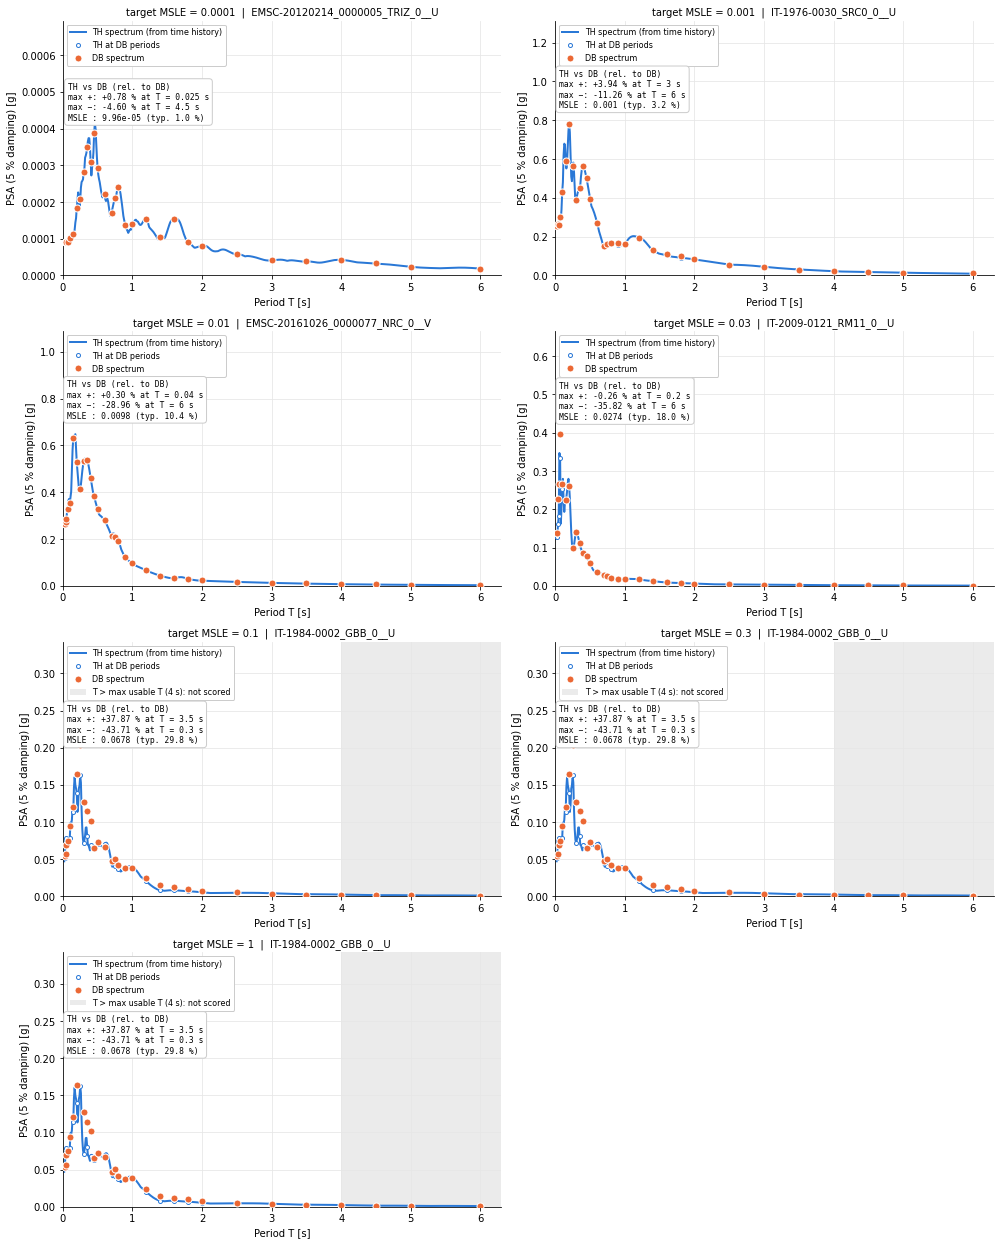

In [6]:
import numpy as np
import matplotlib.pyplot as plt

MSLE_TARGETS = [1e-4, 1e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0]

# Candidates: unambiguous ESM records. NGA-Sub tags start with the numeric RSN, so "not numeric" = ESM.
tags = summary.index.get_level_values("tag")
esm = summary.loc[~summary["ambiguous"] & ~tags.str.match(r"^\d+__")]
log_msle = np.log10(esm["msle"])

# For each target, the record whose log10(MSLE) is closest. Log distance, because the targets are
# spread over decades: "close" should mean close as a ratio, not in absolute terms.
picked = [log_msle.sub(np.log10(t)).abs().idxmin() for t in MSLE_TARGETS]
picked_tbl = esm.loc[picked, ["msle", "max_pos_pct", "T_max_pos", "max_neg_pct", "T_max_neg"]]
picked_tbl.insert(0, "msle_target", MSLE_TARGETS)
display(picked_tbl.round(4))

# two columns, as many rows as needed; any leftover panel (odd number of targets) is hidden
n_rows = int(np.ceil(len(MSLE_TARGETS) / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(14, 4.35 * n_rows))
for ax, (tag, db_row), target in zip(axes.ravel(), picked, MSLE_TARGETS):
    tsv.plot_spectra_comparison(tag, th, db, ax=ax, scale="linear")
    ax.set_title(f"target MSLE = {target:g}  |  {tag}", fontsize=10)
for ax in axes.ravel()[len(MSLE_TARGETS):]:
    ax.set_visible(False)
fig.tight_layout()

## 5. Were components swapped?

Hypothesis: the component labels got swapped somewhere between database and download (the file labelled `__U` holds
the V trace, or vice versa). Test: score each record's TH spectrum against the DB spectrum of the **other** horizontal
component of the same recording (`tsv.swapped_component_check`), with the same periods and MSLE as before (both scores
on the periods up to the lower of the two components' `max_usable_T`). If the swap hypothesis holds, the MSLE against
the other component drops to the faithful range.

With the MSLE the test is run on **every** unambiguous ESM record, with no threshold. The separation is clean: for
every swapped record the other component's MSLE is at most 0.55× its own-label MSLE (median ≈ 0.0002, i.e. ≈1.4 %),
while the closest non-swapped record is at 1.17×.

In [7]:
swap = tsv.swapped_component_check(summary, th, db, database="ESM")      # all ESM records, MSLE

print(f"ESM records tested: {len(swap)}")
print(f"other component fits better: {swap['other_is_lower'].sum()}")
print(f"other component not scorable (missing / ambiguous in DB): {swap['msle_other_component'].isna().sum()}")
ratio = swap["msle_other_component"] / swap["msle_original"]
print(f"other/own MSLE ratio: swapped max {ratio[swap['other_is_lower']].max():.2f}, "
      f"non-swapped min {ratio[~swap['other_is_lower']].min():.2f}")
swap.loc[swap["other_is_lower"]]

ESM records tested: 1032
other component fits better: 0
other component not scorable (missing / ambiguous in DB): 0
other/own MSLE ratio: swapped max nan, non-swapped min 1.43


,msle_original,other_component,msle_other_component,other_is_lower,n_periods
tag,,,,,


`tsv.plot_th_vs_db_components(tag, components=...)` plots the TH spectrum against the DB spectrum of `"U"`, `"V"` or `"both"`
(for NGA-Sub: `"H1"`, `"H2"`, `"both"`). Below: a record the swap explains, and one it does not.

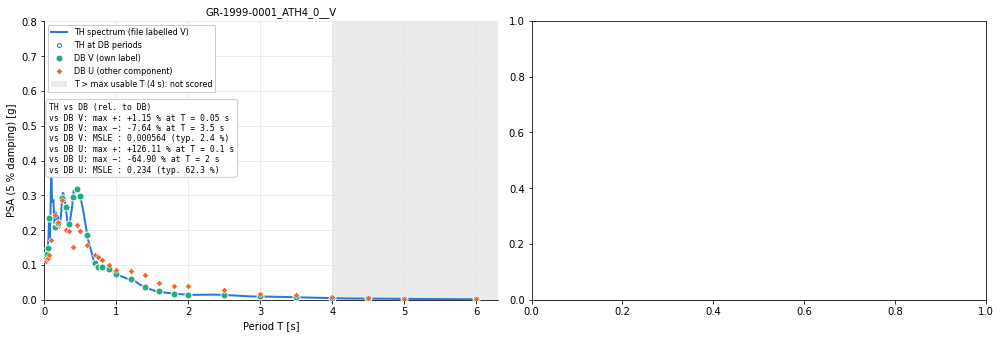

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
tsv.plot_th_vs_db_components("GR-1999-0001_ATH4_0__V", "both", th, db, ax=axes[0], scale="linear")
fig.tight_layout()

In [10]:
# Records identified as SWAPPED: every ESM record whose TH spectrum fits the other component's DB
# spectrum better (MSLE, all ESM records). This includes the two records first found by eye:
#   GR-1995-0030_CHR1_0__V  DB U and V spectra almost identical
#   GR-1985-0007_DRA1_0__U  was masked by DB ordinates beyond its max_usable_T of 3.2 s
swapped_records = sorted(swap.index[swap["other_is_lower"]])
FOUND_BY_EYE = ["GR-1995-0030_CHR1_0__V", "GR-1985-0007_DRA1_0__U"]
print(f"swapped records: {len(swapped_records)}")
print("found-by-eye records caught by the test:", {t: t in swapped_records for t in FOUND_BY_EYE})
swapped_records

swapped records: 0
found-by-eye records caught by the test: {'GR-1995-0030_CHR1_0__V': False, 'GR-1985-0007_DRA1_0__U': False}


[]

### Back to the source files

The JSON converter (`data_handling/convert_esm_records_to_json.py`) takes the station group's datasets in key-sorted order
and labels the **1st U** and the **2nd V**. For every swapped record the original ESM HDF5 file on the HSU share is read
again, converted from cm/s² to g, and the PSA of its 1st and 2nd datasets is computed (same routine and 5 % damping as the
TH spectra). Each is scored against DB U and DB V (`tsv.hdf5_component_check`). `order_as_expected` is True only if
1st → U and 2nd → V. The channel codes of the two datasets are listed too. Needs the share to be reachable.

In [16]:
if swapped_records != []:
    fig, axes = plt.subplots(len(swapped_records), 2, figsize=(14, 4.8 * len(swapped_records)))
    for ax, tag in zip(axes.ravel(), swapped_records):
        tsv.plot_spectra_comparison(tag, th, db, ax=ax, scale="linear")
        ax.set_title(tag)
    fig.tight_layout()
    h5_check = tsv.hdf5_component_check(swapped_records, db)

    print(f"records checked: {len(h5_check)}  (could not be read: {(h5_check['error'] != '').sum()})")
    print(h5_check["order_as_expected"].value_counts().rename(
        index={True: "1st = U and 2nd = V (True)", False: "not in that order (False)"}).to_string())
    print("\nchannel codes of the 1st / 2nd dataset:")
    print(h5_check.groupby(["channel_1", "channel_2"]).size().to_string())
    h5_check

else:
    print("no swapped records found")

no swapped records found


In [17]:
# Control: a few records that are NOT swapped should come out True
tsv.hdf5_component_check(["IT-2012-0011_STS_0__V", "GR-2016-0009_JAN_0__U",
                          "EMSC-20161101_0000060_RM33_0__V"], db)

,channel_1,channel_2,first_matches_U,second_matches_V,order_as_expected,msle_1_vs_U,msle_1_vs_V,msle_2_vs_U,msle_2_vs_V,error
tag,,,,,,,,,,
IT-2012-0011_STS_0__V,HNE,HNN,True,True,True,0.000026,0.167037,0.163662,0.000032,
GR-2016-0009_JAN_0__U,HNE,HNN,True,True,True,0.012342,0.242990,0.368368,0.009786,
EMSC-20161101_0000060_RM33_0__V,HNE,HNN,True,True,True,0.000316,0.196812,0.213930,0.000540,


### Where the swapped records were used in the site-specific MSA

`tsv.msa_record_usage` reads the per-structure collapse-flag JSONs (nb 060, what the MSA actually **ran**, slot by
slot) and checks every hit against the GCIM stripe pickles in `results/04_record_selection/AvgSA_03` (what was
**selected**): the record in slot k of the pickle's `recs` must be the file the MSA ran in slot k, or it raises.
The result is a list of `(site, structure, stripe_iml, record_index)` tuples. `structure` is `"3s"`/`"5s"` and
`stripe_iml` is the file-name token, e.g. `"00pt270"`. It is saved as a CSV (with `record_tag` as an extra column)
in the record set's folder, `06_gm_selection/ss/AvgSA_03__ks/`.

In [18]:
from phd_project.config import config
from phd_project.config.config import load_config

# The MSA whose record usage is looked up: the original SS record set's (the one that ran).
SS_RAN = "AvgSA_03__ks"

if swapped_records != []:
    usage = tsv.msa_record_usage(swapped_records, ss_id=SS_RAN, im="AvgSA_03")   # verifies against the pickles

    # the requested list of (site, structure, stripe_iml, record_index) tuples
    swapped_usage = list(usage[["site", "structure", "stripe_iml", "record_index"]]
                        .itertuples(index=False, name=None))

    # stored with the record set whose MSA used the records
    usage_fp = (config.ss_dir(load_config(), "proc_data", "gm_selection", SS_RAN)
                / "swapped_esm_records_msa_usage_AvgSA_03.csv")
    usage.to_csv(usage_fp, index=False)

    print(f"uses: {len(swapped_usage)}  ({usage['structure'].value_counts().to_dict()}), "
        f"sites: {usage['site'].nunique()}, "
        f"structure-stripes: {usage.groupby(['site', 'structure', 'stripe_iml']).ngroups}")
    print(f"swapped records used at least once: {usage['record_tag'].nunique()} of {len(swapped_records)}")
    print(f"never used in the MSA: {sorted(set(swapped_records) - set(usage['record_tag']))}")
    print(f"\nsaved to:   {usage_fp}")
    swapped_usage[:10]

## 6. Channel naming in all the ESM HDF5 files

The converter (`data_handling/convert_esm_records_to_json.py`) never looks at channel **names**. It takes the station
group's datasets in key-sorted order and calls the 1st U, the 2nd V and the 3rd W, which its docstring justifies as
"sorted E/N/Z". That is only right when the two horizontals are an E and an N channel. Here every HDF5 file on the share
is scanned (`tsv.scan_esm_hdf5_channels`; only the dataset keys are read, and the result is cached in
`07_gm_records/esm_hdf5_channel_inventory.csv`). For each file this records the channel codes in the converter's order.

`tsv.summarise_channel_layouts` groups the files by the (1st, 2nd) channel pair:
* `matches_converter_assumption`: the 1st/2nd channels end in E and N, the order the converter assumes.
* `n_downloaded_tags` and `n_other_component_fits_better`: how many of the downloaded records come from that layout,
  and how many of those fit the other component's DB spectrum better (the §5 test over all ESM records).

In [19]:
inventory = tsv.scan_esm_hdf5_channels()       # reads the cached CSV unless the share changed
print(f"HDF5 files: {len(inventory)}   unreadable: {(inventory['error'] != '').sum()}")
print("\ndatasets per file (3 = one instrument; more = several instruments in one file):")
print(inventory["n_datasets"].value_counts().sort_index().to_string())
print("\nfull channel lists (converter order):")
print(inventory.groupby("all_channels").size().sort_values(ascending=False).to_string())

layouts = tsv.summarise_channel_layouts(inventory, summary, th, db)
layouts

HDF5 files: 21688   unreadable: 0

datasets per file (3 = one instrument; more = several instruments in one file):
n_datasets
3    21659
6       22
9        7

full channel lists (converter order):
all_channels
HNE/HNN/HNZ                            16320
HGE/HGN/HGZ                             4646
HN2/HN3/HNZ                              442
HLE/HLN/HLZ                              248
HNE/HNN/HNZ/HGE/HGN/HGZ                   22
HNE/HNN/HNZ/HN2/HN3/HNZ/HN2/HN3/HNZ        7
HG2/HG3/HGZ                                2
HN1/HN2/HNZ                                1


,channel_1,channel_2,orientation_codes,n_files,matches_converter_assumption,n_downloaded_tags,n_other_component_fits_better
0,HNE,HNN,E/N,16349,True,697,0
1,HGE,HGN,E/N,4646,True,276,0
2,HN2,HN3,2/3,442,False,41,0
3,HLE,HLN,E/N,248,True,18,0
4,HG2,HG3,2/3,2,False,0,0
5,HN1,HN2,1/2,1,False,0,0


In [20]:
# Files holding more than one instrument: the converter takes the first two datasets in sorted
# order, whichever instrument they belong to.
inventory.loc[inventory["n_datasets"] > 3, ["file", "n_datasets", "all_channels"]]

,file,n_datasets,all_channels
3320,EMSC-20140407_0000141__OGFO__00.h5,9,HNE/HNN/HNZ/HN2/HN3/HNZ/HN2/HN3/HNZ
4919,EMSC-20141224_0000053__SGPA__00.h5,6,HNE/HNN/HNZ/HGE/HGN/HGZ
4921,EMSC-20141224_0000053__SGSC__00.h5,6,HNE/HNN/HNZ/HGE/HGN/HGZ
7189,EMSC-20151206_0000082__SGPA__00.h5,6,HNE/HNN/HNZ/HGE/HGN/HGZ
7190,EMSC-20151206_0000082__SGSC__00.h5,6,HNE/HNN/HNZ/HGE/HGN/HGZ
7403,EMSC-20160116_0000069__SGPA__00.h5,6,HNE/HNN/HNZ/HGE/HGN/HGZ
7404,EMSC-20160116_0000069__SGSC__00.h5,6,HNE/HNN/HNZ/HGE/HGN/HGZ
7871,EMSC-20160824_0000006__SGPA__00.h5,6,HNE/HNN/HNZ/HGE/HGN/HGZ
7872,EMSC-20160824_0000006__SGSC__00.h5,6,HNE/HNN/HNZ/HGE/HGN/HGZ
8148,EMSC-20160824_0000013__SGPA__00.h5,6,HNE/HNN/HNZ/HGE/HGN/HGZ


## 7. Large errors that a swap does not explain

The ESM records that are **not** swapped (`other_is_lower == False` in the §5 `swap` table) but still fit poorly:
own-label MSLE > `MSLE_LARGE` = 0.05, a typical error of ≈25 %. Each is plotted against both DB components, on linear
axes, for inspection. The poor fits form a continuous tail rather than a separate group (the next record, at 0.0495,
sits just below the threshold; 20 non-swapped records are above 0.02), so the threshold is a choice, not a gap.

records: 21


,msle_original,other_component,msle_other_component,other_is_lower,n_periods
tag,,,,,
IT-1984-0002_GBB_0__U,0.067847,V,0.239739,False,28
IT-1980-0012_BNV_0__U,0.065111,V,0.120776,False,31
IT-2009-0102_MI05_0__V,0.046324,U,0.570664,False,31
IT-1980-0012_BSC_0__V,0.045500,U,0.065288,False,31
IT-2009-0102_RM04_0__U,0.044630,V,0.358062,False,31
IT-1980-0012_BNV_0__V,0.039531,U,0.101157,False,31
IT-1980-0012_BSC_0__U,0.034465,V,0.153079,False,31
IT-2009-0121_RM11_0__U,0.027384,V,0.148495,False,31
IT-1984-0002_GBB_0__V,0.020979,U,0.315597,False,28


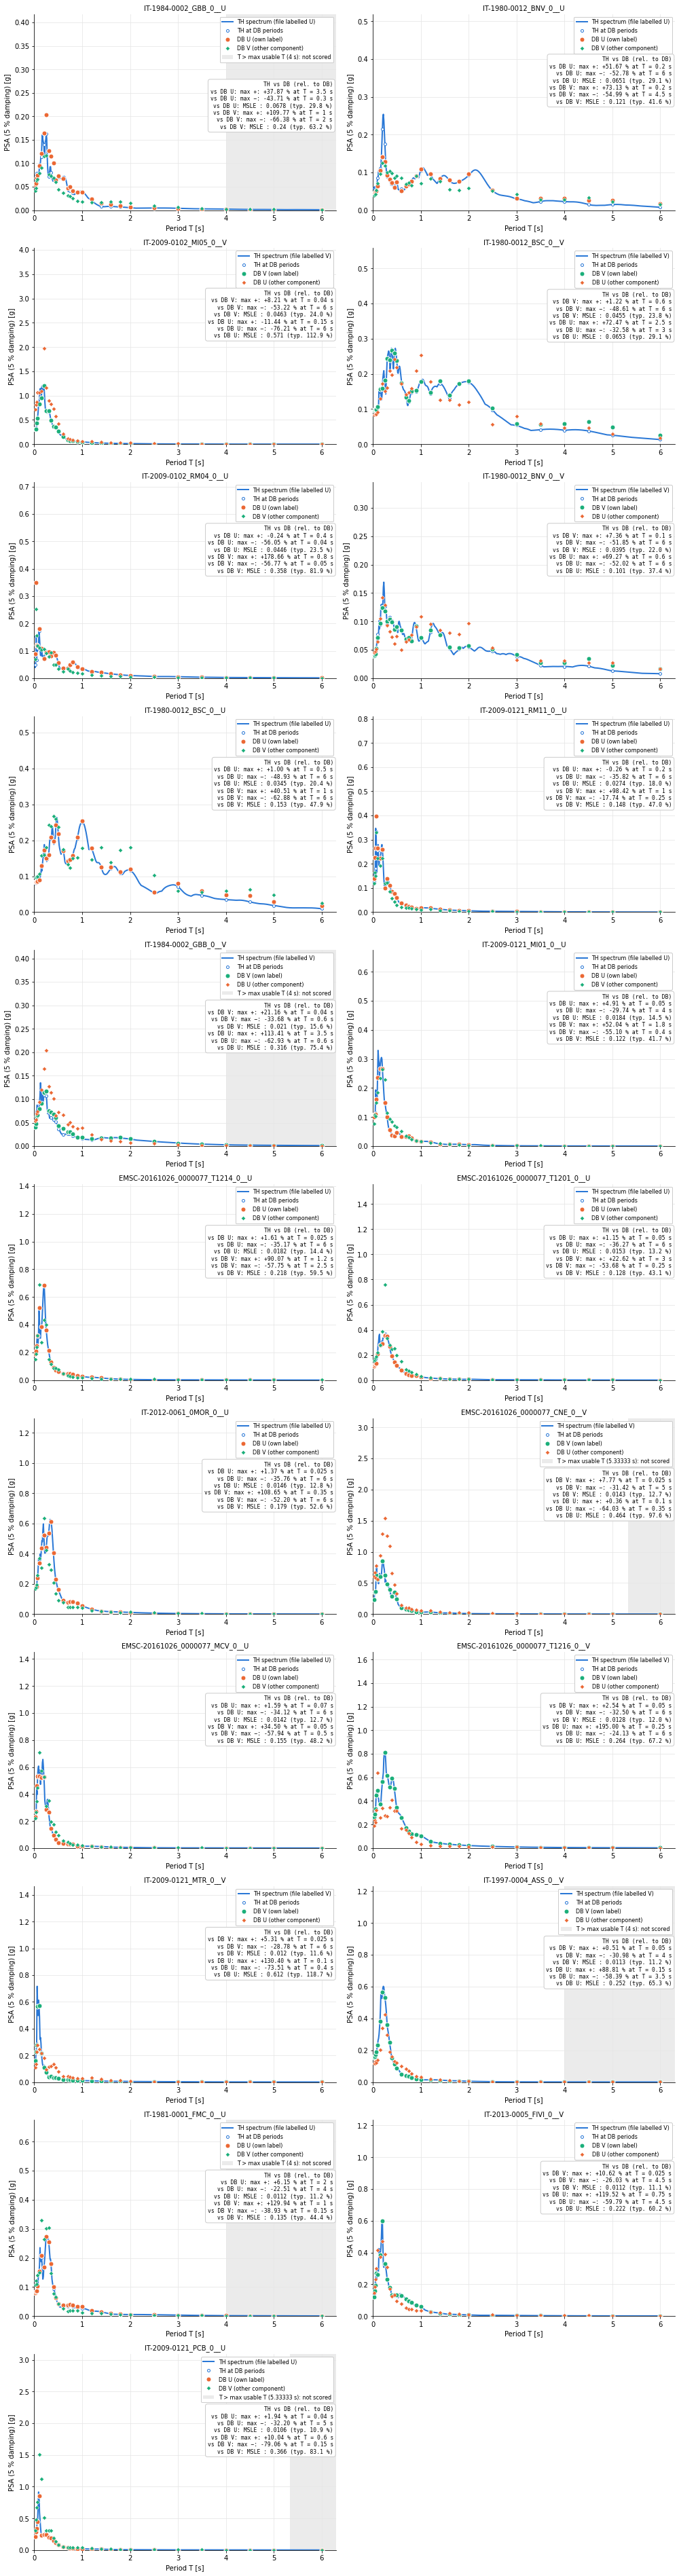

In [21]:
MSLE_LARGE = 0.01

unexplained = swap.loc[~swap["other_is_lower"] & (swap["msle_original"] > MSLE_LARGE)]
print(f"records: {len(unexplained)}")
display(unexplained)

# two per row; any leftover panel (odd count) is hidden. Legends top right: these spectra peak at
# short periods, so the top-left corner is where the data is.
n_rows = int(np.ceil(len(unexplained) / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(14, 4.8 * n_rows), squeeze=False)
for ax, tag in zip(axes.ravel(), unexplained.index):
    tsv.plot_th_vs_db_components(tag, "both", th, db, ax=ax, scale="linear",
                                 legend_loc="upper right")
for ax in axes.ravel()[len(unexplained):]:
    ax.set_visible(False)
fig.tight_layout()

## 8. Manual review of the non-swap fits with MSLE > 0.01

Every ESM record in the §7 grid with `MSLE_LARGE = 0.01` (51 records, two per row, in the order of the
`unexplained` table) was inspected by eye (2026-09-30). The plots at these **(row, column)** coordinates were judged
**suboptimal fits**:

(0,0), (1,0), (1,1), (2,0), (3,0), (4,0), (4,1), (5,1), (6,0), (6,1), (9,1), (18,1)

Coordinate (r, c) is record `2·r + c` of `unexplained`. The cell below turns the coordinates into record tags, so the
list stays tied to the grid it was read from.

In [26]:
# (row, column) of the plots judged suboptimal in the MSLE > 0.01 grid of section 7
SUBOPTIMAL_COORDS = [(0, 0), (0, 1), (1, 1), (2, 0), (2, 1), (3, 0), (3, 1),
                     (4,0)]
# the coordinates only mean something for the grid they were read from
if not (MSLE_LARGE == 0.01 and len(unexplained) == 21):
    print("section 7 grid is not the reviewed one")

else:
    suboptimal = pd.DataFrame(
        [(rc, unexplained.index[2 * rc[0] + rc[1]]) for rc in SUBOPTIMAL_COORDS],
        columns=["grid_coord", "tag"]).set_index("tag")
    suboptimal["msle"] = unexplained.loc[suboptimal.index, "msle_original"]
    suboptimal_records = suboptimal.index.tolist()
    suboptimal

### How often the suboptimal records were used in the site-specific MSA

`tsv.msa_record_usage` (as for the swapped records in §5): every (site, structure, stripe, slot) in which each record
was run, checked against the stripe pickles. Per record: the number of runs, and the number of distinct sites,
structures (site × storey) and structure-stripes.

In [27]:
sub_usage = tsv.msa_record_usage(suboptimal_records, ss_id="AvgSA_03__ks", im="AvgSA_03")

g = sub_usage.groupby("record_tag")
use_summary = pd.DataFrame({
    "n_uses": g.size(),
    "n_sites": g["site"].nunique(),
    "n_structures": g.apply(lambda d: d.groupby(["site", "structure"]).ngroups, include_groups=False),
    "n_structure_stripes": g.apply(lambda d: d.groupby(["site", "structure", "stripe_iml"]).ngroups,
                                   include_groups=False),
    "n_3s": g["structure"].apply(lambda s: (s == "3s").sum()),
    "n_5s": g["structure"].apply(lambda s: (s == "5s").sum()),
}).reindex(suboptimal_records).fillna(0).astype(int)      # never-used records get zeros
use_summary.insert(0, "grid_coord", suboptimal["grid_coord"])

print(f"total runs using a suboptimal record: {use_summary['n_uses'].sum()} "
      f"at {sub_usage['site'].nunique()} sites, "
      f"{sub_usage.groupby(['site', 'structure', 'stripe_iml']).ngroups} structure-stripes")
print(f"records never used in the MSA: {(use_summary['n_uses'] == 0).sum()} of {len(use_summary)}")
use_summary.sort_values("n_uses", ascending=False)

total runs using a suboptimal record: 163 at 36 sites, 130 structure-stripes
records never used in the MSA: 1 of 8


,grid_coord,n_uses,n_sites,n_structures,n_structure_stripes,n_3s,n_5s
record_tag,,,,,,,
IT-1980-0012_BSC_0__U,"(3, 0)",78,23,42,78,36,42
IT-1980-0012_BNV_0__V,"(2, 1)",27,12,21,27,11,16
IT-1980-0012_BNV_0__U,"(0, 1)",20,11,17,20,8,12
IT-1980-0012_BSC_0__V,"(1, 1)",14,9,12,14,7,7
IT-2009-0102_RM04_0__U,"(2, 0)",10,8,10,10,5,5
IT-1984-0002_GBB_0__V,"(4, 0)",8,4,6,8,5,3
IT-2009-0121_RM11_0__U,"(3, 1)",6,3,6,6,3,3
IT-1984-0002_GBB_0__U,"(0, 0)",0,0,0,0,0,0
